# 07 - Explainable AI with SHAP and LIME

This notebook explains the same depth-4 balanced decision tree evaluated in Notebook 04. Its test performance is **92.60% accuracy, 30.58% precision, 92.65% recall, and 45.99% F1-score**.

The model is examined from two perspectives:

- **Global explanation:** Which features influence the model across the test set?
- **Local explanation:** Why did the model make one specific prediction?

Global SHAP summarizes all 2,000 test predictions. Local SHAP and LIME then explain one declared example of each confusion-matrix outcome. Correct cases reveal learned patterns, while errors expose rules that may be too broad or incomplete. Explanations describe model behavior; they do not prove physical causation or guarantee that the behavior is responsible.

## 1. The four prediction outcomes

| Case | Actual value | Model prediction | Research meaning |
|---|---:|---:|---|
| True positive (TP) | Failure | Failure | The model correctly detected a failure. |
| False positive (FP) | No failure | Failure | False alarm; may cause unnecessary maintenance. |
| False negative (FN) | Failure | No failure | Missed failure; usually the most safety-critical error. |
| True negative (TN) | No failure | No failure | The model correctly recognized normal operation. |

The current test set contains **63 true positives, 143 false positives, five false negatives, and 1,789 true negatives**. An AI researcher should inspect both correct and incorrect cases because error explanations are often more useful for improving reliability than explanations of successful predictions alone.

## 2. Import libraries and locate the project

The classifier, preprocessing, and explanation functions are reused from the project package. This ensures that Notebook 07 explains the exact workflow evaluated earlier rather than rebuilding a subtly different model. A fixed random seed also makes the train/test split and LIME perturbation sampling reproducible.

In [2]:
from pathlib import Path
import sys

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display


def find_project_root(start_path):
    """Walk upward until the predictive_maintenance package is found."""
    for candidate in [start_path, *start_path.parents]:
        if (candidate / "src" / "predictive_maintenance").exists():
            return candidate
    raise FileNotFoundError("Could not locate the project root.")


PROJECT_ROOT = find_project_root(Path.cwd().resolve())
SRC_DIR = PROJECT_ROOT / "src"
if str(SRC_DIR) not in sys.path:
    sys.path.insert(0, str(SRC_DIR))

from predictive_maintenance.classification import FailureClassificationExperiment
from predictive_maintenance.config import INPUT_FEATURES, OUTPUTS_DIR
from predictive_maintenance.data_loader import load_ai4i_dataset
from predictive_maintenance.explainability import (
    lime_local_explanation,
    shap_global_importance,
    shap_local_explanation,
)

XAI_OUTPUT_DIR = OUTPUTS_DIR / "explainable_ai"
FIGURE_DIR = XAI_OUTPUT_DIR / "figures"
XAI_OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
FIGURE_DIR.mkdir(parents=True, exist_ok=True)

pd.set_option("display.max_columns", 20)
pd.set_option("display.float_format", lambda value: f"{value:.4f}")

print(f"Project root: {PROJECT_ROOT}")

Project root: /Users/bijaypandey/Documents/Uni of Regina/ENSE_861/responsible_ai_project


## 3. Load data and train the same classifier

We use the same decision tree configuration as the classification stage: maximum depth 4, balanced class weights, and a 0.5 decision threshold. Keeping the model fixed is essential; otherwise, the explanations would describe a different model from the reported evaluation.

Only the six safe input features are used. Failure-mode columns are not model inputs because they would leak information about the target. The reproduced confusion matrix is `[[1789, 143], [5, 63]]`.

In [5]:
data = load_ai4i_dataset()

experiment = FailureClassificationExperiment(
    max_depth=4,
    class_weight="balanced",
)
experiment.fit(data)

metrics = experiment.metrics_frame(threshold=0.5)
display(metrics)
print(experiment.classification_report(threshold=0.5))

,accuracy,precision,recall,f1,confusion_matrix,threshold
0,0.9260,0.3058,0.9265,0.4599,"[[1789, 143], [5, 63]]",0.5000


              precision    recall  f1-score   support

  No failure       1.00      0.93      0.96      1932
     Failure       0.31      0.93      0.46        68

    accuracy                           0.93      2000
   macro avg       0.65      0.93      0.71      2000
weighted avg       0.97      0.93      0.94      2000



At threshold 0.5, the model catches **63 of 68 failures** but only **63 of 206 failure alerts** are correct. This produces high recall (0.9265) and low precision (0.3058). Explainability cannot remove this tradeoff, but it can reveal the sensor patterns behind correct detections, false alarms, and missed failures.

## 4. Label every prediction as TP, FP, FN, or TN

Every prediction is assigned to one of the four confusion-matrix outcomes. Original sensor values are retained because the model receives standardized values, while an engineer interprets temperatures, rpm, torque, and tool wear in their original units.

The measured counts are 63 TP, 143 FP, 5 FN, and 1,789 TN. These counts also verify that the case labelling matches the confusion matrix from Notebook 04.

In [3]:
predictions = experiment.predictions_frame(threshold=0.5).reset_index()
predictions = predictions.rename(columns={"index": "dataset_row_index"})

actual = predictions["actual_machine_failure"]
predicted = predictions["predicted_machine_failure"]

predictions["case_type"] = np.select(
    [
        (actual == 1) & (predicted == 1),
        (actual == 0) & (predicted == 1),
        (actual == 1) & (predicted == 0),
        (actual == 0) & (predicted == 0),
    ],
    ["true_positive", "false_positive", "false_negative", "true_negative"],
    default="unclassified",
)

case_order = ["true_positive", "false_positive", "false_negative", "true_negative"]
case_counts = (
    predictions["case_type"]
    .value_counts()
    .reindex(case_order, fill_value=0)
    .rename_axis("case_type")
    .reset_index(name="count")
)

display(case_counts)
predictions.to_csv(XAI_OUTPUT_DIR / "xai_prediction_examples_source.csv", index=False)

,case_type,count
0,true_positive,63
1,false_positive,143
2,false_negative,5
3,true_negative,1789


## 5. Select one example of each outcome

For a transparent first analysis, the notebook selects the first test-set occurrence of each case. The selected test positions are 17 (TP), 0 (FP), 121 (FN), and 1 (TN), with failure probabilities 0.9661, 0.8637, 0.0308, and 0.0308, respectively.

In a larger study, selection should follow a declared protocol, for example:

- the most confident error,
- the error nearest the decision threshold,
- a random sample with a fixed seed, or
- all errors, summarized as a group.

Declaring the selection rule reduces cherry-picking. Four examples are illustrative case studies, not evidence that every TP, FP, FN, or TN has the same explanation. Group-level error analysis is still required.

In [4]:
example_rows = {}
for case_name in case_order:
    matching_positions = predictions.index[predictions["case_type"] == case_name].tolist()
    if matching_positions:
        example_rows[case_name] = matching_positions[0]

example_index = predictions.loc[
    list(example_rows.values()),
    [
        "case_type",
        "dataset_row_index",
        "actual_machine_failure",
        "predicted_machine_failure",
        "predicted_failure_probability",
    ],
].copy()
example_index.insert(1, "test_row_position", list(example_rows.values()))

display(example_index)
example_index.to_csv(XAI_OUTPUT_DIR / "xai_local_example_index.csv", index=False)

,case_type,test_row_position,dataset_row_index,actual_machine_failure,predicted_machine_failure,predicted_failure_probability
17,true_positive,17,4851,1,1,0.9661
0,false_positive,0,2997,0,1,0.8637
121,false_negative,121,9174,1,0,0.0308
1,true_negative,1,4871,0,0,0.0308


## 6. Global SHAP explanation

SHAP is based on Shapley values from cooperative game theory. Features act as players, the model output acts as the payoff, and each value $\phi_j$ represents a feature's allocated contribution relative to a baseline. Local additivity is:

$$f(x)=E[f(X)]+\sum_{j=1}^{p}\phi_j$$

For this balanced tree, the SHAP baseline failure output is **0.500**. Positive contributions raise the failure output above 0.5; negative contributions lower it.

For global importance, the notebook calculates the mean absolute SHAP value over all test records:

$$I_j = \frac{1}{n}\sum_{i=1}^{n}|\phi_{ij}|$$

Here, $\phi_{ij}$ is the SHAP contribution of feature $j$ for record $i$. The absolute value measures strength regardless of direction. Global importance therefore tells us **how much** a feature changes predictions on average, but not whether high values consistently increase risk. `TreeExplainer` is used because it computes efficient, model-faithful SHAP values for the decision tree.

/Users/bijaypandey/Documents/Uni of Regina/ENSE_861/responsible_ai_project/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


,feature,mean_absolute_shap_value
2,numeric__Rotational speed,0.1736
3,numeric__Torque,0.1606
4,numeric__Tool wear,0.1472
0,numeric__Air temperature,0.0593
1,numeric__Process temperature,0.0088
5,categorical__Type_H,0.0000
6,categorical__Type_L,0.0000
7,categorical__Type_M,0.0000


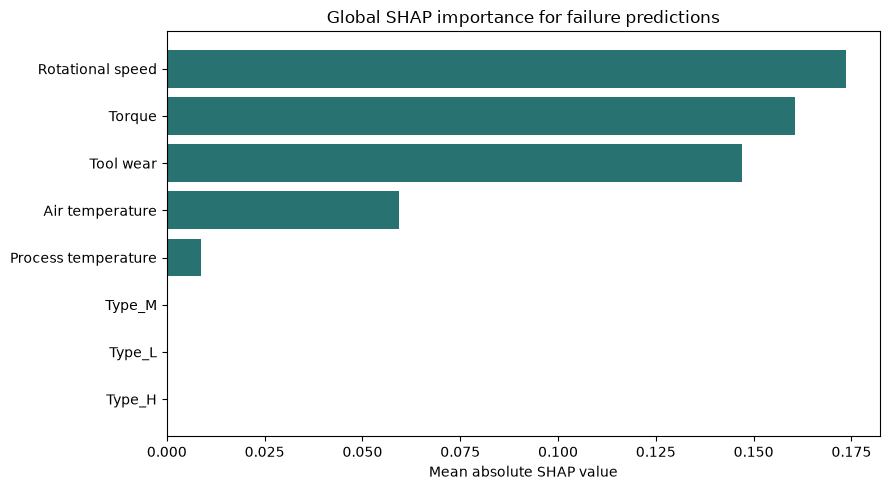

In [5]:
shap_importance = shap_global_importance(
    experiment.model,
    experiment.split_data,
)

display(shap_importance)
shap_importance.to_csv(XAI_OUTPUT_DIR / "shap_global_importance.csv", index=False)

plot_data = shap_importance.sort_values("mean_absolute_shap_value")
fig, ax = plt.subplots(figsize=(9, 5))
ax.barh(
    plot_data["feature"].str.replace("numeric__", "", regex=False).str.replace("categorical__", "", regex=False),
    plot_data["mean_absolute_shap_value"],
    color="#287271",
)
ax.set_title("Global SHAP importance for failure predictions")
ax.set_xlabel("Mean absolute SHAP value")
ax.set_ylabel("")
fig.tight_layout()
fig.savefig(FIGURE_DIR / "shap_global_importance.png", dpi=200, bbox_inches="tight")
plt.show()

### Global interpretation

The measured mean absolute SHAP values are **0.1736 for rotational speed, 0.1606 for torque, 0.1472 for tool wear, 0.0593 for air temperature, and 0.0088 for process temperature**. All machine-type indicators receive zero importance in this fitted tree.

This ranking agrees with the earlier impurity-based decision-tree importance. Agreement across methods strengthens the conclusion that speed, torque, and wear are central to this model's behavior.

However, this is still **model importance**, not physical causality. Correlated features can share or redistribute contributions, and zero model importance does not prove that machine type or process temperature is irrelevant to the real system.

## 7. How to read local SHAP and LIME values

**Local SHAP** explains the fitted tree relative to its baseline:

- positive value: raises the failure output above the 0.500 baseline;
- negative value: lowers the failure output;
- larger absolute value: stronger influence on this prediction;
- baseline plus all contributions: reconstructs the model output.

**Local LIME** creates perturbed samples around one record, obtains the black-box model's predictions, weights nearby perturbations more heavily, and fits an interpretable local linear surrogate $g$:

$$g^*=\arg\min_g\;L(f,g,\pi_x)+\Omega(g)$$

Here, $L$ measures how closely the surrogate matches model $f$ near record $x$, $\pi_x$ gives nearby samples greater weight, and $\Omega(g)$ penalizes explanation complexity.

- positive LIME weight supports failure locally;
- negative LIME weight supports no failure locally;
- larger absolute weight means greater local surrogate influence.

The conditions shown by LIME and the `transformed_feature_value` shown by SHAP are in the model's preprocessed space. For numerical features, values are standardized z-scores. For example, `Torque > 0.68` means more than 0.68 training-set standard deviations above the training mean, not 0.68 Nm.

LIME weights do not directly add to the predicted probability because the surrogate also has an intercept and approximation error. SHAP and LIME need not agree perfectly: SHAP allocates the tree output among features, while LIME estimates behavior in a sampled local neighborhood.

Two limitations matter here. Correlated sensors can make contribution allocation ambiguous, and the current LIME helper treats transformed one-hot type columns as numerical perturbation variables. Their LIME weights are very small in these examples, but a more rigorous implementation should declare those columns categorical and report local surrogate fidelity.

## 8. Helper for displaying one local explanation

The helper displays and saves three pieces of evidence together:

1. the original sensor measurements and prediction,
2. the SHAP contributions, and
3. the LIME local conditions and weights.

The plots use green for evidence toward failure and blue for evidence toward no failure. CSV files preserve exact values for auditing, while PNG figures provide report- and presentation-ready summaries.

In [6]:
def clean_feature_name(name):
    return name.replace("numeric__", "").replace("categorical__", "")


def clean_lime_condition(condition):
    return condition.replace("numeric__", "").replace("categorical__", "")


def explain_case(case_name):
    """Compute, display, plot, and save SHAP/LIME evidence for one case."""
    row_position = example_rows[case_name]

    summary_columns = [
        "dataset_row_index",
        *INPUT_FEATURES,
        "actual_machine_failure",
        "predicted_machine_failure",
        "predicted_failure_probability",
    ]
    record = predictions.loc[[row_position], summary_columns]

    shap_table = shap_local_explanation(
        experiment.model,
        experiment.split_data,
        row_position=row_position,
    )
    lime_table = lime_local_explanation(
        experiment.model,
        experiment.split_data,
        row_position=row_position,
    )

    shap_saved = shap_table.copy()
    shap_saved.insert(0, "case_type", case_name)
    shap_saved.insert(1, "test_row_position", row_position)
    lime_saved = lime_table.copy()
    lime_saved.insert(0, "case_type", case_name)
    lime_saved.insert(1, "test_row_position", row_position)

    shap_saved.to_csv(XAI_OUTPUT_DIR / f"shap_local_{case_name}.csv", index=False)
    lime_saved.to_csv(XAI_OUTPUT_DIR / f"lime_local_{case_name}.csv", index=False)

    print(f"{case_name.replace('_', ' ').title()} | test position {row_position}")
    display(record)
    print("SHAP explanation")
    display(shap_table)
    print("LIME explanation")
    display(lime_table)

    shap_plot = shap_table.sort_values("shap_value_for_failure")
    lime_plot = lime_table.sort_values("lime_weight_for_failure")
    fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))

    shap_colors = np.where(shap_plot["shap_value_for_failure"] >= 0, "#2a9d8f", "#457b9d")
    axes[0].barh(
        shap_plot["feature"].map(clean_feature_name),
        shap_plot["shap_value_for_failure"],
        color=shap_colors,
    )
    axes[0].axvline(0, color="black", linewidth=0.8)
    axes[0].set_title("SHAP contributions")
    axes[0].set_xlabel("Contribution toward failure (+) or no failure (-)")

    lime_colors = np.where(lime_plot["lime_weight_for_failure"] >= 0, "#2a9d8f", "#457b9d")
    axes[1].barh(
        lime_plot["lime_condition"].map(clean_lime_condition),
        lime_plot["lime_weight_for_failure"],
        color=lime_colors,
    )
    axes[1].axvline(0, color="black", linewidth=0.8)
    axes[1].set_title("LIME local weights")
    axes[1].set_xlabel("Local weight toward failure (+) or no failure (-)")

    fig.suptitle(case_name.replace("_", " ").title(), fontsize=14)
    fig.tight_layout()
    fig.savefig(FIGURE_DIR / f"local_{case_name}_shap_lime.png", dpi=200, bbox_inches="tight")
    plt.show()

    return {"record": record, "shap": shap_table, "lime": lime_table}


## 9. True positive: correctly detected failure

Research questions:

- Which features pushed the model toward failure?
- Do SHAP and LIME agree on the main evidence?
- Is the explanation plausible when compared with the original sensor values?

True Positive | test position 17


,dataset_row_index,Type,Air temperature,Process temperature,Rotational speed,Torque,Tool wear,actual_machine_failure,predicted_machine_failure,predicted_failure_probability
17,4851,L,303.7000,312.1000,1363,51.8000,90,1,1,0.9661


SHAP explanation


,feature,transformed_feature_value,shap_value_for_failure,absolute_shap_value
2,numeric__Rotational speed,-0.9745,0.4132,0.4132
0,numeric__Air temperature,1.8503,0.1966,0.1966
3,numeric__Torque,1.1774,-0.0922,0.0922
4,numeric__Tool wear,-0.2780,-0.0816,0.0816
1,numeric__Process temperature,1.4155,0.0302,0.0302
5,categorical__Type_H,0.0000,0.0000,0.0000
6,categorical__Type_L,1.0000,0.0000,0.0000
7,categorical__Type_M,0.0000,0.0000,0.0000


LIME explanation


,lime_condition,lime_weight_for_failure
0,numeric__Torque > 0.68,0.1688
1,numeric__Rotational speed <= -0.65,0.1601
2,numeric__Air temperature > 0.75,0.1512
3,-0.86 < numeric__Tool wear <= -0.01,-0.0763
4,numeric__Process temperature > 0.74,-0.0216
5,categorical__Type_H <= 0.00,0.0122
6,categorical__Type_M <= 0.00,0.0036
7,0.00 < categorical__Type_L <= 1.00,0.0007


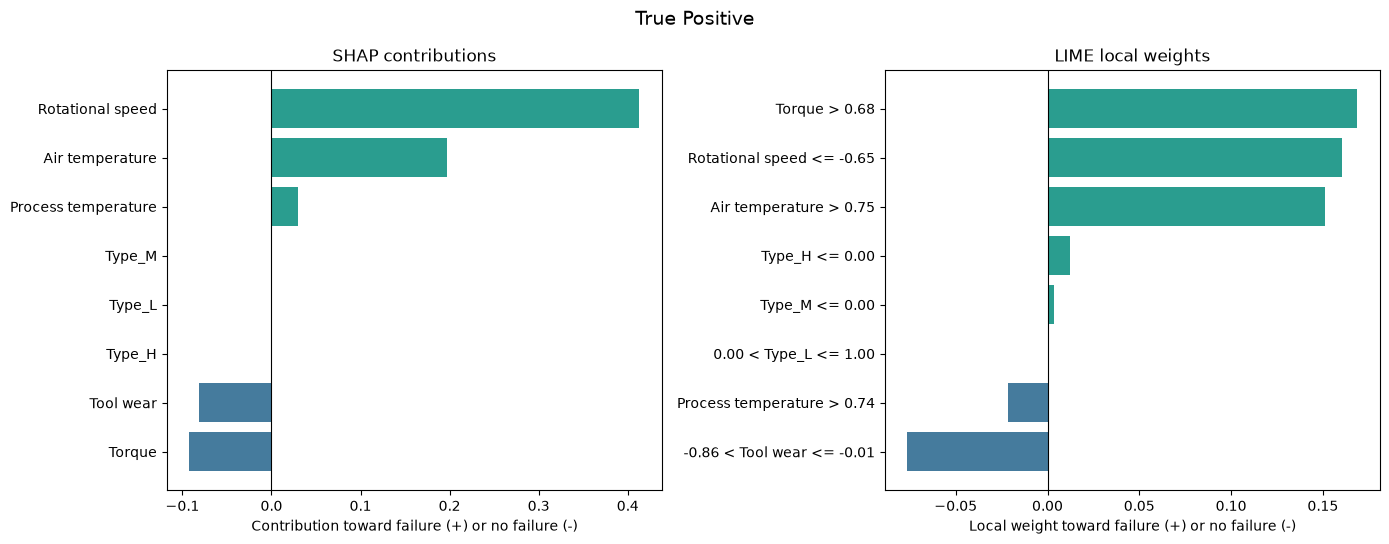

In [7]:
true_positive_explanation = explain_case("true_positive")

### True-positive interpretation

The selected true positive is dataset row 4,851: type L, air temperature 303.7 K, process temperature 312.1 K, rotational speed 1,363 rpm, torque 51.8 Nm, and tool wear 90 minutes. The model correctly assigns failure probability **0.9661**.

Starting from the 0.500 SHAP baseline, the contributions sum to **+0.4661**. Low rotational speed contributes **+0.4132**, high air temperature **+0.1966**, and process temperature **+0.0302** toward failure. Torque contributes **-0.0922** and tool wear **-0.0816** toward no failure. Thus, the strong speed and temperature evidence dominates the negative contributions.

LIME also treats low rotational speed (**+0.1601**) and high air temperature (**+0.1512**) as failure-supporting. This cross-method agreement strengthens the local interpretation.

Torque deserves attention: LIME treats the high-torque region as positive evidence (**+0.1688**), while SHAP assigns torque a negative contribution for the exact tree output. This is not automatically an implementation error. SHAP allocates the tree prediction globally across feature coalitions, whereas LIME approximates nearby perturbations. The responsible interpretation reports agreement on speed and temperature and treats the torque disagreement as an interaction or stability question requiring further investigation.

## 10. False positive: false maintenance alarm

A false positive reveals why the system would request unnecessary maintenance. The selected case is dataset row 2,997 and receives a high failure probability despite having a no-failure label.

False Positive | test position 0


,dataset_row_index,Type,Air temperature,Process temperature,Rotational speed,Torque,Tool wear,actual_machine_failure,predicted_machine_failure,predicted_failure_probability
0,2997,L,300.5000,309.8000,1345,62.7000,153,0,1,0.8637


SHAP explanation


,feature,transformed_feature_value,shap_value_for_failure,absolute_shap_value
3,numeric__Torque,2.2654,0.3708,0.3708
2,numeric__Rotational speed,-1.0740,0.1350,0.1350
0,numeric__Air temperature,0.2477,-0.0767,0.0767
4,numeric__Tool wear,0.7124,-0.0672,0.0672
1,numeric__Process temperature,-0.1393,0.0018,0.0018
5,categorical__Type_H,0.0000,0.0000,0.0000
6,categorical__Type_L,1.0000,0.0000,0.0000
7,categorical__Type_M,0.0000,0.0000,0.0000


LIME explanation


,lime_condition,lime_weight_for_failure
0,numeric__Torque > 0.68,0.1732
1,numeric__Rotational speed <= -0.65,0.1481
2,-0.01 < numeric__Tool wear <= 0.87,-0.0589
3,0.05 < numeric__Air temperature <= 0.75,-0.0471
4,categorical__Type_H <= 0.00,0.0214
5,-0.82 < numeric__Process temperature <= 0.06,0.0062
6,categorical__Type_M <= 0.00,0.0049
7,0.00 < categorical__Type_L <= 1.00,-0.0012


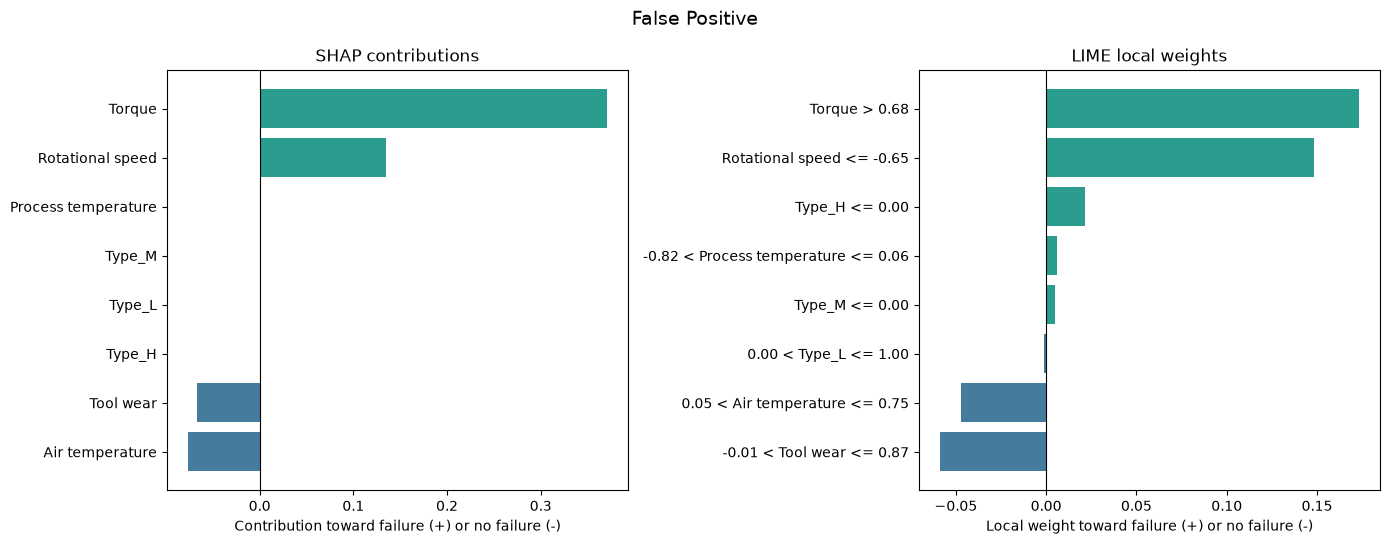

In [8]:
false_positive_explanation = explain_case("false_positive")

### False-positive interpretation

This type-L record has rotational speed **1,345 rpm**, torque **62.7 Nm**, and tool wear **153 minutes**. The model predicts failure probability **0.8637**. Relative to the 0.500 baseline, SHAP contributions sum to **+0.3637**.

SHAP identifies torque (**+0.3708**) and low rotational speed (**+0.1350**) as the main failure evidence. Air temperature (**-0.0767**) and tool wear (**-0.0672**) oppose the alert but are not strong enough to reverse it. LIME independently gives its two largest positive weights to high torque (**+0.1732**) and low speed (**+0.1481**).

The agreement gives a clear model-level explanation of the false alarm: this record strongly matches the learned high-torque, low-speed failure region even though its dataset label is no failure.

This does not prove that the model is irrational or that the label is wrong. The record may be a difficult boundary case, no failure may have occurred during the observation window, or the class-weighted tree rule may be too broad. The research follow-up is to measure how many of the 143 false positives share this torque-speed pattern.

## 11. False negative: missed failure

This is the most important case for risk analysis because the equipment failed but the model predicted no failure. The selected case is dataset row 9,174.

False Negative | test position 121


,dataset_row_index,Type,Air temperature,Process temperature,Rotational speed,Torque,Tool wear,actual_machine_failure,predicted_machine_failure,predicted_failure_probability
121,9174,L,297.8000,308.9000,1871,25.6000,200,1,0,0.0308


SHAP explanation


,feature,transformed_feature_value,shap_value_for_failure,absolute_shap_value
2,numeric__Rotational speed,1.8326,-0.2597,0.2597
3,numeric__Torque,-1.4376,-0.1295,0.1295
4,numeric__Tool wear,1.4513,-0.0597,0.0597
0,numeric__Air temperature,-1.1045,-0.0226,0.0226
1,numeric__Process temperature,-0.7477,0.0022,0.0022
5,categorical__Type_H,0.0000,0.0000,0.0000
6,categorical__Type_L,1.0000,0.0000,0.0000
7,categorical__Type_M,0.0000,0.0000,0.0000


LIME explanation


,lime_condition,lime_weight_for_failure
0,numeric__Tool wear > 0.87,0.1947
1,numeric__Air temperature <= -0.85,-0.0572
2,numeric__Rotational speed > 0.41,-0.0484
3,numeric__Torque <= -0.68,-0.0431
4,categorical__Type_H <= 0.00,0.0186
5,-0.82 < numeric__Process temperature <= 0.06,0.0060
6,categorical__Type_M <= 0.00,0.0057
7,0.00 < categorical__Type_L <= 1.00,0.0019


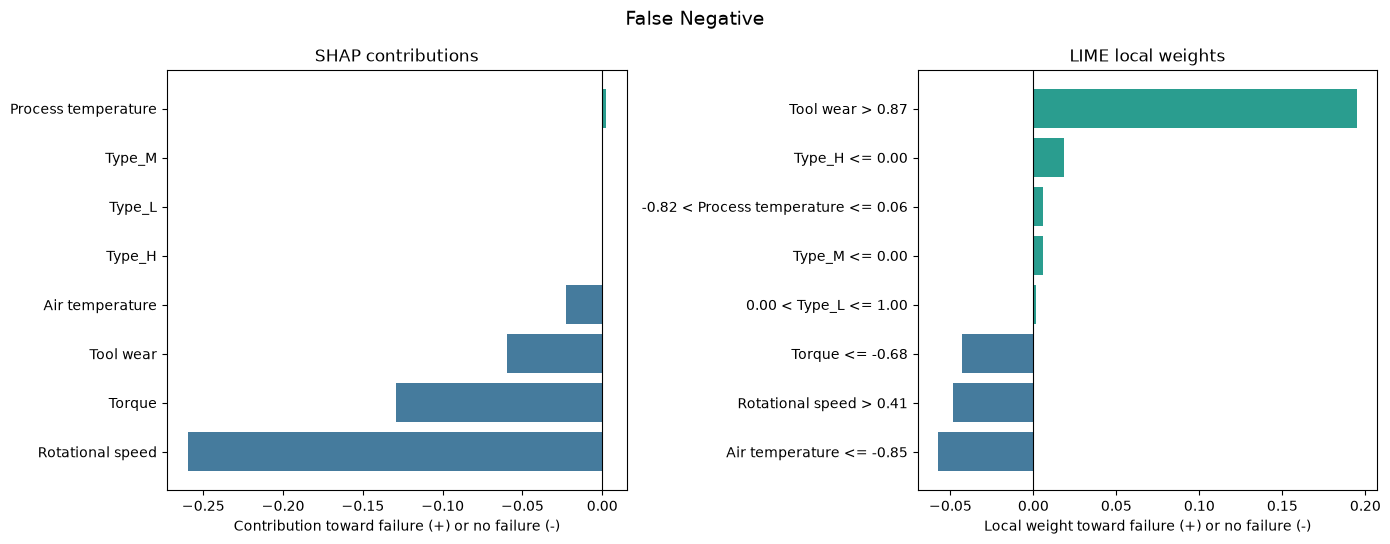

In [9]:
false_negative_explanation = explain_case("false_negative")

### False-negative interpretation

The type-L record has air temperature **297.8 K**, process temperature **308.9 K**, rotational speed **1,871 rpm**, torque **25.6 Nm**, and tool wear **200 minutes**. Despite the high wear, the model assigns failure probability only **0.0308**.

The SHAP contributions sum to **-0.4692** relative to the 0.500 baseline. High rotational speed contributes **-0.2597**, low torque **-0.1295**, tool wear **-0.0597**, and air temperature **-0.0226** toward no failure. The tree therefore interprets this combined operating region as strongly non-failing.

LIME recognizes high tool wear as substantial local failure evidence (**+0.1947**), but gives negative weights to the high-speed, low-torque, and low-air-temperature regions. This suggests that the wear warning is locally present but is outweighed in the model's decision.

SHAP assigning wear a negative contribution while LIME assigns high wear a positive weight is a meaningful disagreement. It may reflect tree interactions, different reference questions, or LIME approximation behavior. Because only five false negatives exist, all five should be inspected to determine whether high-speed, low-torque, high-wear failures form a repeated blind spot.

## 12. True negative: correctly recognized no failure

A true negative helps identify the evidence the model considers sufficiently consistent with no failure. The selected case is dataset row 4,871.

True Negative | test position 1


,dataset_row_index,Type,Air temperature,Process temperature,Rotational speed,Torque,Tool wear,actual_machine_failure,predicted_machine_failure,predicted_failure_probability
1,4871,L,303.7000,312.4000,1513,40.1000,135,0,0,0.0308


SHAP explanation


,feature,transformed_feature_value,shap_value_for_failure,absolute_shap_value
3,numeric__Torque,0.0096,-0.1679,0.1679
2,numeric__Rotational speed,-0.1456,-0.1470,0.1470
4,numeric__Tool wear,0.4294,-0.1156,0.1156
1,numeric__Process temperature,1.6182,-0.0608,0.0608
0,numeric__Air temperature,1.8503,0.0221,0.0221
5,categorical__Type_H,0.0000,0.0000,0.0000
6,categorical__Type_L,1.0000,0.0000,0.0000
7,categorical__Type_M,0.0000,0.0000,0.0000


LIME explanation


,lime_condition,lime_weight_for_failure
0,numeric__Air temperature > 0.75,0.1422
1,-0.01 < numeric__Tool wear <= 0.87,-0.0575
2,-0.20 < numeric__Rotational speed <= 0.41,-0.0551
3,-0.68 < numeric__Torque <= 0.01,-0.0501
4,categorical__Type_H <= 0.00,0.0236
5,numeric__Process temperature > 0.74,-0.0189
6,categorical__Type_M <= 0.00,0.0085
7,0.00 < categorical__Type_L <= 1.00,0.0004


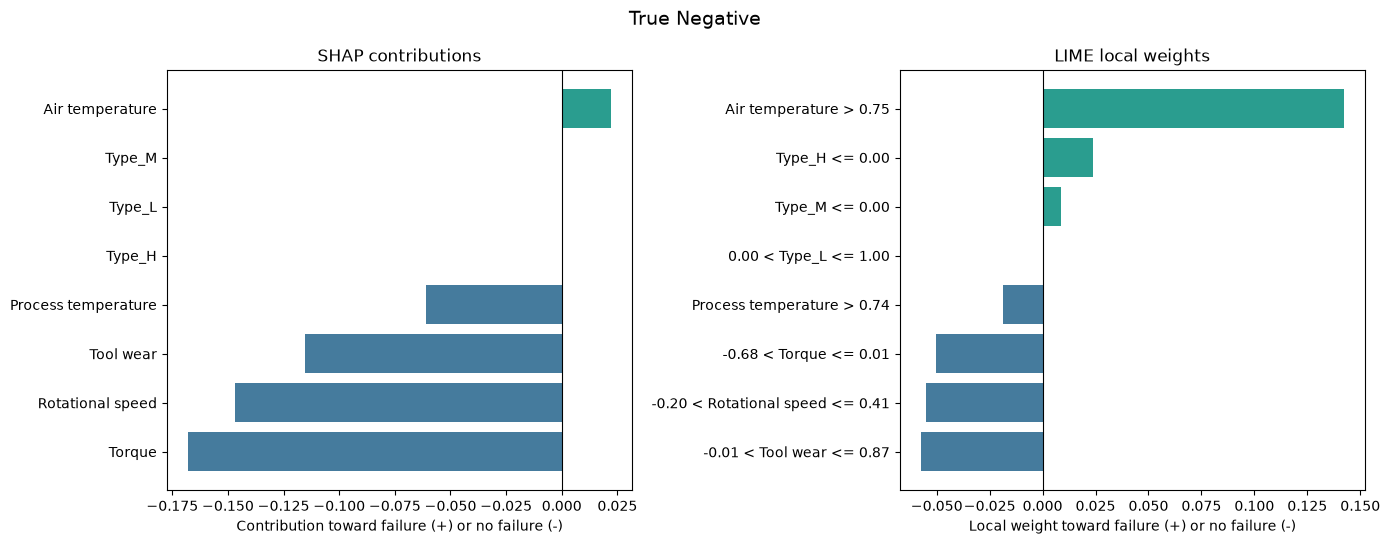

In [10]:
true_negative_explanation = explain_case("true_negative")

### True-negative interpretation

This type-L record has air temperature **303.7 K**, process temperature **312.4 K**, rotational speed **1,513 rpm**, torque **40.1 Nm**, and tool wear **135 minutes**. The model correctly assigns failure probability **0.0308**.

SHAP contributions sum to **-0.4692**. Torque (**-0.1679**), rotational speed (**-0.1470**), tool wear (**-0.1156**), and process temperature (**-0.0608**) support no failure. Air temperature provides a small opposing contribution (**+0.0221**). LIME similarly identifies the wear, speed, torque, and process-temperature regions as negative evidence, although high air temperature receives a positive local weight (**+0.1422**).

This illustrates why a prediction should not be explained with one sensor. The correct no-failure result comes from combined evidence, and even a strong local warning from air temperature is insufficient to reverse the tree's overall decision.

## 13. Compare all four cases

The comparison table summarizes the dominant SHAP evidence:

| Case | Failure probability | Strongest toward failure | SHAP | Strongest toward no failure | SHAP |
|---|---:|---|---:|---|---:|
| True positive | 0.9661 | Rotational speed | +0.4132 | Torque | -0.0922 |
| False positive | 0.8637 | Torque | +0.3708 | Air temperature | -0.0767 |
| False negative | 0.0308 | Process temperature | +0.0022 | Rotational speed | -0.2597 |
| True negative | 0.0308 | Air temperature | +0.0221 | Torque | -0.1679 |

The false negative has almost no positive SHAP support, showing how confidently the tree places it in a no-failure region. The false negative and true negative receive the same leaf probability, 0.0308, but their contribution patterns differ. A decision tree can therefore produce the same output for different records while SHAP reveals different paths of supporting evidence.

In [11]:
all_explanations = {
    "true_positive": true_positive_explanation,
    "false_positive": false_positive_explanation,
    "false_negative": false_negative_explanation,
    "true_negative": true_negative_explanation,
}

comparison_rows = []
for case_name, result in all_explanations.items():
    shap_table = result["shap"]
    strongest_failure = shap_table.loc[shap_table["shap_value_for_failure"].idxmax()]
    strongest_no_failure = shap_table.loc[shap_table["shap_value_for_failure"].idxmin()]
    prediction_row = predictions.loc[example_rows[case_name]]

    comparison_rows.append(
        {
            "case_type": case_name,
            "failure_probability": prediction_row["predicted_failure_probability"],
            "strongest_SHAP_toward_failure": clean_feature_name(strongest_failure["feature"]),
            "positive_SHAP_value": strongest_failure["shap_value_for_failure"],
            "strongest_SHAP_toward_no_failure": clean_feature_name(strongest_no_failure["feature"]),
            "negative_SHAP_value": strongest_no_failure["shap_value_for_failure"],
        }
    )

case_comparison = pd.DataFrame(comparison_rows)
display(case_comparison)
case_comparison.to_csv(XAI_OUTPUT_DIR / "xai_case_comparison.csv", index=False)

,case_type,failure_probability,strongest_SHAP_toward_failure,positive_SHAP_value,strongest_SHAP_toward_no_failure,negative_SHAP_value
0,true_positive,0.9661,Rotational speed,0.4132,Torque,-0.0922
1,false_positive,0.8637,Torque,0.3708,Air temperature,-0.0767
2,false_negative,0.0308,Process temperature,0.0022,Rotational speed,-0.2597
3,true_negative,0.0308,Air temperature,0.0221,Torque,-0.1679


## 14. How an AI researcher evaluates explanations

An explanation should not be accepted only because its plot looks reasonable. For this experiment:

1. **Faithfulness:** Tree SHAP satisfies local additivity here; baseline plus contributions exactly reconstructs each model output. LIME fidelity is not yet quantified and should be reported in a stronger evaluation.
2. **Stability:** LIME uses a fixed seed for reproducibility, but explanations should be repeated across seeds and small sensor perturbations to test stability.
3. **Consistency:** Both methods agree strongly on the false positive's high-torque, low-speed pattern. They disagree on torque in the TP and tool wear in the FN, so complete cross-method agreement cannot be claimed.
4. **Representativeness:** One declared example per case prevents hidden selection, but four records cannot represent all 2,000 predictions. Group-level SHAP analysis is needed for all 143 false positives and all five false negatives.
5. **Domain plausibility:** Highlighted speed, torque, wear, and temperature patterns should be compared with the engineered relationships and maintenance knowledge.
6. **Non-causality:** A contribution explains the model's learned calculation, not the physical cause of failure.
7. **Human interpretability:** LIME conditions are currently expressed as standardized values, which are less intuitive than rpm, Nm, and minutes. Report communication should pair them with original sensor values.

The most important next research step is therefore group-level error explanation: determine whether the false-positive torque-speed pattern and false-negative high-speed, low-torque, high-wear pattern recur across the complete error sets.

## 15. Responsible and Explainable AI contribution

The global SHAP analysis identifies rotational speed, torque, and tool wear as the classifier's dominant features. Local case analysis shows that SHAP and LIME can provide understandable evidence for correct predictions and errors. The clearest agreement occurs for the false positive, where both methods identify high torque and low rotational speed as the reason for a high failure output. The false negative exposes a potential blind spot: the model strongly interprets high speed and low torque as no-failure evidence despite high tool wear.

This supports **transparency** by exposing learned sensor patterns, **accountability** by documenting why false alarms and missed failures occur, and **robustness assessment** by identifying behavior requiring further testing. Explainability does not make the model automatically responsible. The results remain local, non-causal, sensitive to reference and perturbation choices, and dependent on the quality of the trained classifier.

The exact global values, four local SHAP tables, four local LIME tables, case index, comparison table, and five figures are saved under `outputs/explainable_ai/`. These artifacts provide traceable evidence for the final report and presentation.